# 02 — Preprocessing & features
Variance sensor selection, condition normalisation (KMeans k=6 on FD002/FD004), smoothing, causal rolling features, sequences.

In [1]:
import sys; sys.path.insert(0,'..')
import yaml,numpy as np,pandas as pd
from src.data import load_split,add_rul_train,add_piecewise_rul
from src.preprocess import *
from src.train import prepare_subset,build_feature_store
cfg=yaml.safe_load(open('../config.yaml' if __import__('pathlib').Path('../config.yaml').exists() else 'config.yaml'))
print(cfg)

{'seed': 42, 'rul_cap': 125, 'rul_cap_ablation': [100, 125, 130], 'window_length': 30, 'window_ablation': [20, 30, 50], 'rolling_windows': [10, 30], 'smooth_alpha': 0.3, 'kmeans_k': 6, 'test_size': 0.2, 'n_splits_cv': 5, 'seeds': [42, 43, 44], 'deep_epochs': 60, 'deep_patience': 8, 'deep_subsample_frac': 0.6, 'bootstrap_resamples': 1000, 'sensors_drop_fd001': [], 'variance_threshold': 1e-06, 'class_thresholds': {'warning_low': 20, 'warning_high': 50, 'binary': 30}, 'cost_matrix': {'missed_failure': 10.0, 'false_alarm': 1.0, 'late_warning_cost': 2.0}, 'randomized_search_iter': 12, 'artifacts': {'figures': 'figures', 'results': 'results', 'models': 'models'}}


In [2]:
train,test_all,_=prepare_subset('FD001','../data/raw' if __import__('pathlib').Path('../data/raw').exists() else 'data/raw',cfg)
store=build_feature_store(train.copy(),test_all.copy(),cfg,'FD001')
print('sensors kept:',store['sensors'])
print('dropped:',store['dropped'])
print('feature dim:',store['Xtr'].shape)
import pandas as pd; print(pd.Series(store['feat_cols']).head(20).tolist())

sensors kept: ['s13', 's17', 's15', 's14', 's12', 's11', 's9', 's8', 's7', 's6', 's4', 's3', 's2', 's20', 's21']
dropped: ['s1', 's19', 's18', 's5', 's16', 's10']
feature dim: (20631, 94)
['s13', 's17', 's15', 's14', 's12', 's11', 's9', 's8', 's7', 's6', 's4', 's3', 's2', 's20', 's21', 's13_rm10', 's13_rs10', 's13_rm30', 's13_rs30', 's17_rm10']


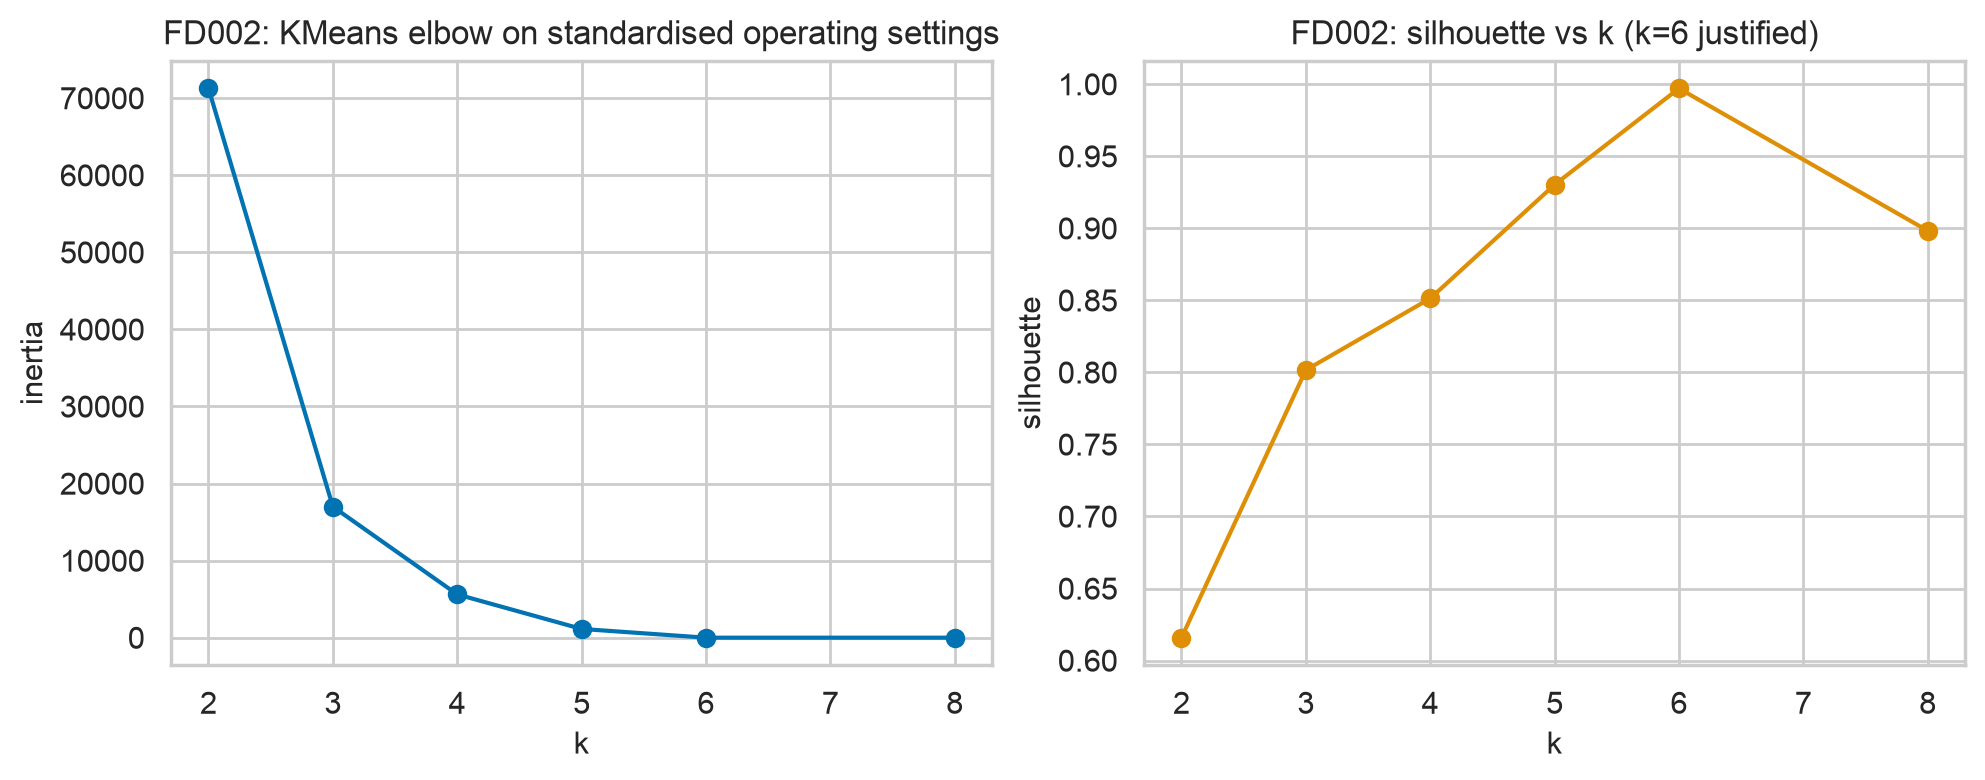

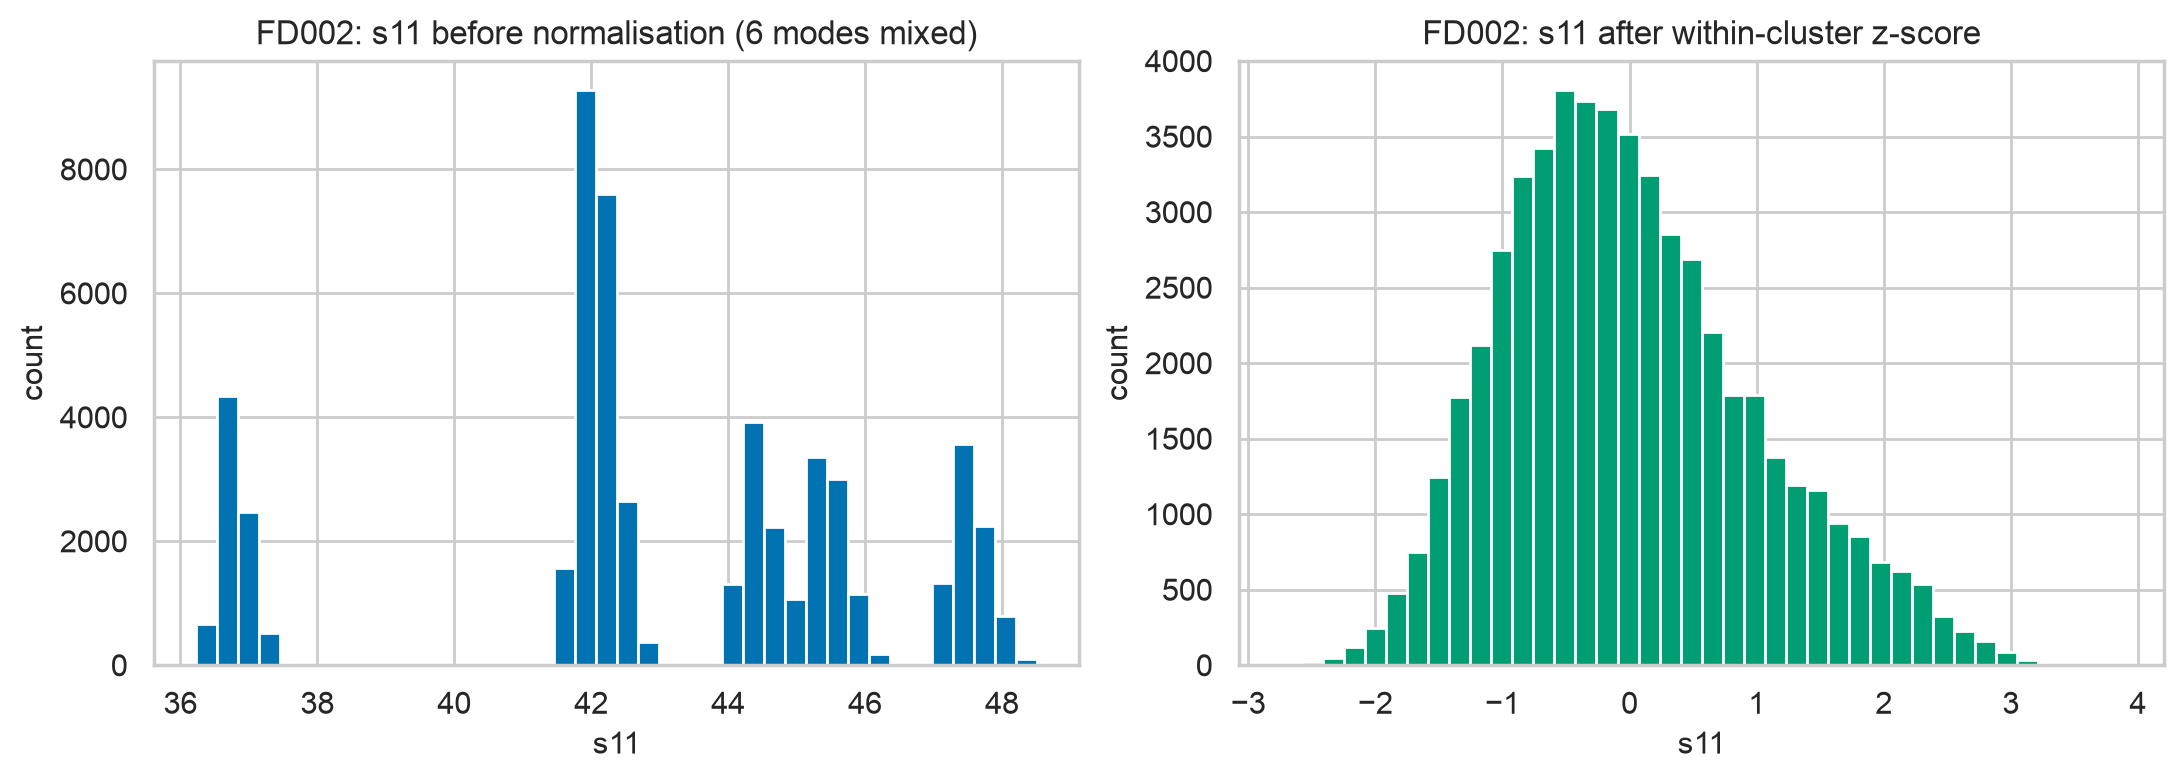

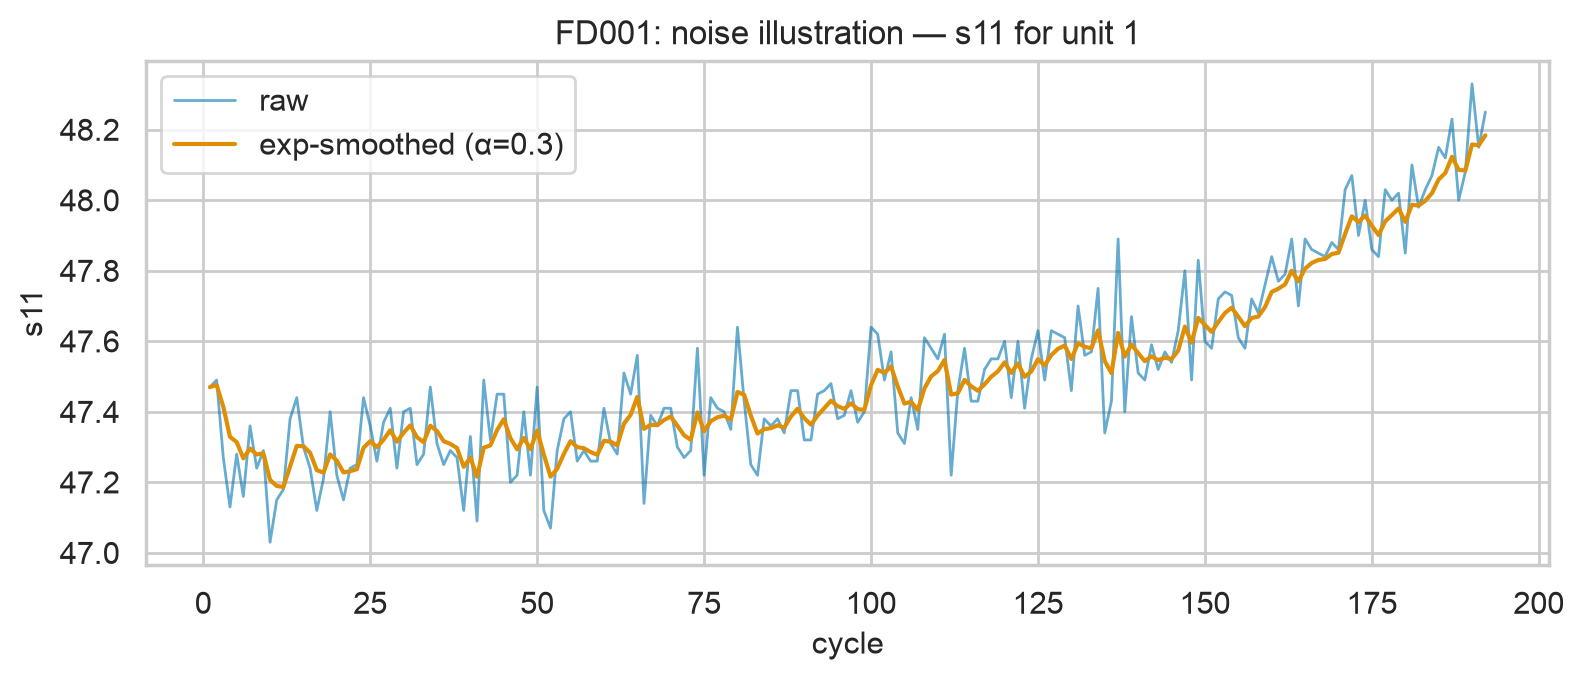

In [3]:
from IPython.display import Image, display
for f in ['FD002_kmeans_select.png','FD002_condnorm_effect.png','FD001_smoothing.png']:
    import pathlib
    for base in ['../figures/','figures/']:
        p=pathlib.Path(base+f)
        
        if p.exists():
            display(Image(filename=str(p),width=700)); break